# Mastodon × Spark — Visualisations (partie 5)

Graphiques construits à partir des tables PostgreSQL remplies par le pipeline :

| Graphique | Source |
|---|---|
| Fréquence des toots dans le temps | `toots` (streaming) |
| Activité jour × heure (heatmap) | `toots` (streaming) |
| Top 15 hashtags | `batch_hashtag_totals` (batch) |
| Distribution des sentiments | `toot_sentiment` (MLlib) |
| Sentiment par hashtag | `toot_sentiment` × `toot_hashtags` |
| Optimisation du batch | `batch_benchmarks` |
| Qualité du modèle | `sentiment_model_metrics` |

Avant d'exécuter : lancer `batch/batch_job.py` et `ml/score_toots.py` pour des résultats à jour (cf. README).
Les textes des graphiques sont en anglais (réutilisés dans les slides de la soutenance) ; chaque figure est
aussi enregistrée en PNG dans `notebooks/figures/`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from sqlalchemy import create_engine

# Connexion : depuis le conteneur Jupyter (POSTGRES_HOST=postgres) ou depuis la machine hôte (port 5433)
host = os.environ.get("POSTGRES_HOST", "localhost")
port = 5432 if host == "postgres" else int(os.environ.get("POSTGRES_HOST_PORT", "5433"))
engine = create_engine(
    f"postgresql+psycopg2://{os.environ.get('POSTGRES_USER', 'mastodon')}:"
    f"{os.environ.get('POSTGRES_PASSWORD', 'mastodon')}@{host}:{port}/{os.environ.get('POSTGRES_DB', 'mastodon')}"
)


def sql(query: str) -> pd.DataFrame:
    return pd.read_sql(query, engine)


FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

# Palette (validée daltonisme) : sentiment = polarité -> pôles bleu / rouge et gris neutre au milieu ;
# magnitude (heatmap) -> une seule teinte, du clair au foncé.
BLUE, RED, GRAY, MUTED = "#2a78d6", "#e34948", "#a3a29c", "#c9c8c2"
TEXT, TEXT_2 = "#0b0b0b", "#52514e"
SENTIMENT_COLORS = {"negative": RED, "neutral": GRAY, "positive": BLUE}
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": MUTED, "axes.labelcolor": TEXT_2, "text.color": TEXT,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def finish(fig, name: str):
    sns.despine(fig=fig, left=True)
    fig.savefig(FIGURES / f"{name}.png")
    plt.show()

In [2]:
overview = sql("""
    SELECT (SELECT count(*) FROM toots)                          AS toots,
           (SELECT count(DISTINCT user_id) FROM toots)           AS users,
           (SELECT count(DISTINCT hashtag) FROM toot_hashtags)   AS hashtags,
           (SELECT count(*) FROM toot_sentiment)                 AS scored_toots,
           (SELECT min(ingested_at) FROM toots)                  AS collection_start,
           (SELECT max(ingested_at) FROM toots)                  AS last_toot
""")
overview.T.rename(columns={0: "valeur"})

,valeur
toots,12376
users,3102
hashtags,12798
scored_toots,9280
collection_start,2026-10-09 20:06:11.288923+00:00
last_toot,2026-10-09 22:03:48.468315+00:00


## 1. Fréquence des toots dans le temps

Toots par heure de publication (`created_at`, UTC) sur les derniers jours. Avant le début de la collecte,
les toots viennent du *backfill* (les 200 derniers toots de chaque hashtag) : la courbe y est incomplète.

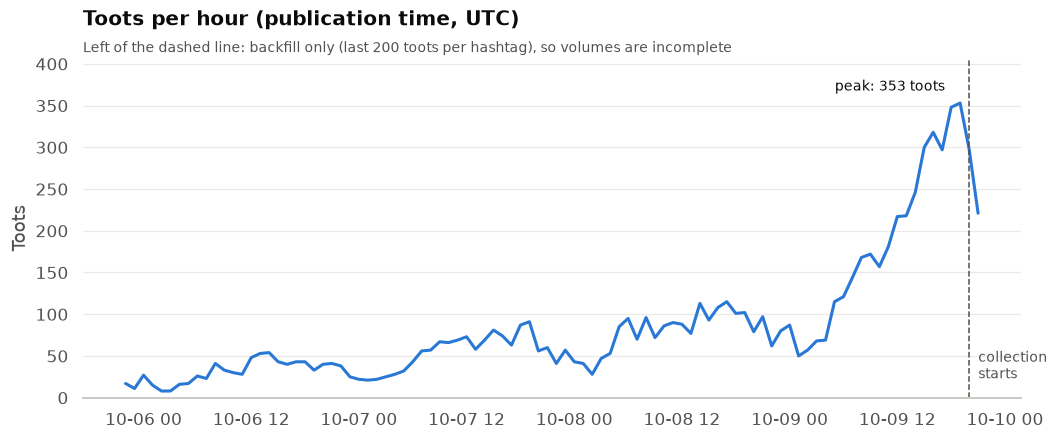

In [3]:
hourly = sql("""
    SELECT date_trunc('hour', created_at) AS hour, count(*) AS toots
    FROM toots
    WHERE created_at >= (SELECT max(created_at) FROM toots) - interval '4 days'
    GROUP BY 1 ORDER BY 1
""")
# Heures sans toot : 0 (et non une interpolation entre deux points)
hourly = hourly.set_index("hour").asfreq("h", fill_value=0).reset_index().iloc[:-1]  # heure en cours exclue
start = overview.collection_start[0].floor("h")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hourly.hour, hourly.toots, color=BLUE, linewidth=2)
ax.axvline(start, color=TEXT_2, linewidth=1, linestyle="--")
ax.annotate("collection\nstarts", xy=(start, hourly.toots.max() * 0.05), xytext=(6, 0),
            textcoords="offset points", ha="left", va="bottom", color=TEXT_2, fontsize=9)
ax.text(0, 1.02, "Left of the dashed line: backfill only (last 200 toots per hashtag), so volumes are incomplete",
        transform=ax.transAxes, color=TEXT_2, fontsize=9)
peak = hourly.loc[hourly.toots.idxmax()]
ax.annotate(f"peak: {peak.toots:,} toots", xy=(peak.hour, peak.toots), xytext=(-10, 6),
            textcoords="offset points", ha="right", va="bottom", color=TEXT, fontsize=9)
ax.set_ylim(0, hourly.toots.max() * 1.15)
ax.set_title("Toots per hour (publication time, UTC)", pad=22)
ax.set_xlabel("")
ax.set_ylabel("Toots")
ax.grid(axis="x", visible=False)
finish(fig, "1_toots_per_hour")

**Lecture (10/10/2026).** La hausse régulière avant le début de la collecte est un **artefact du backfill** :
on ne récupère que les 200 derniers toots de chaque hashtag, donc plus on remonte dans le temps, moins on a
de toots. Seule la partie à droite du trait pointillé reflète le vrai rythme de publication. En mode
polling, la limite de l'API (300 requêtes / 5 min) impose des pauses : le mode streaming (avec un token)
capterait tous les toots en temps réel.

## 2. Activité par jour et par heure

Nombre de toots par jour et par heure de publication (UTC), sur les 5 derniers jours.

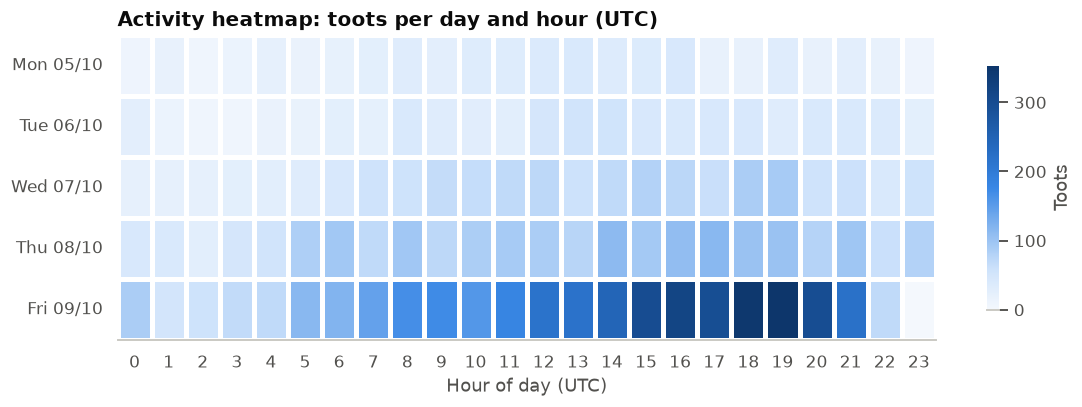

In [4]:
activity = sql("""
    SELECT created_at::date AS day, extract(hour FROM created_at)::int AS hour, count(*) AS toots
    FROM toots
    WHERE created_at >= (SELECT max(created_at)::date FROM toots) - 4
    GROUP BY 1, 2
""")
grid = (activity.pivot(index="day", columns="hour", values="toots")
        .reindex(columns=range(24)).fillna(0).astype(int))
grid.index = pd.to_datetime(grid.index).strftime("%a %d/%m")

fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(grid, cmap=SEQUENTIAL, linewidths=2, linecolor="white", cbar_kws={"label": "Toots", "shrink": 0.8},
            ax=ax)
ax.set_title("Activity heatmap: toots per day and hour (UTC)")
ax.set_xlabel("Hour of day (UTC)")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
finish(fig, "2_activity_heatmap")

**Lecture.** L'activité se concentre l'après-midi et en soirée UTC (environ 12 h – 21 h), ce qui correspond
à la journée en Europe et à la matinée en Amérique du Nord, où se trouve l'essentiel des utilisateurs de
mastodon.social. Comme pour le graphique précédent, les jours les plus anciens sont sous-représentés
par le backfill : la comparaison entre jours est biaisée, celle entre heures d'un même jour l'est beaucoup moins.

## 3. Top 15 hashtags

Totaux du job batch. Pour chaque hashtag, on calcule aussi la part du compte qui l'utilise le plus :
au-delà de 50 %, le volume du hashtag reflète surtout l'activité d'un seul compte (souvent un bot).

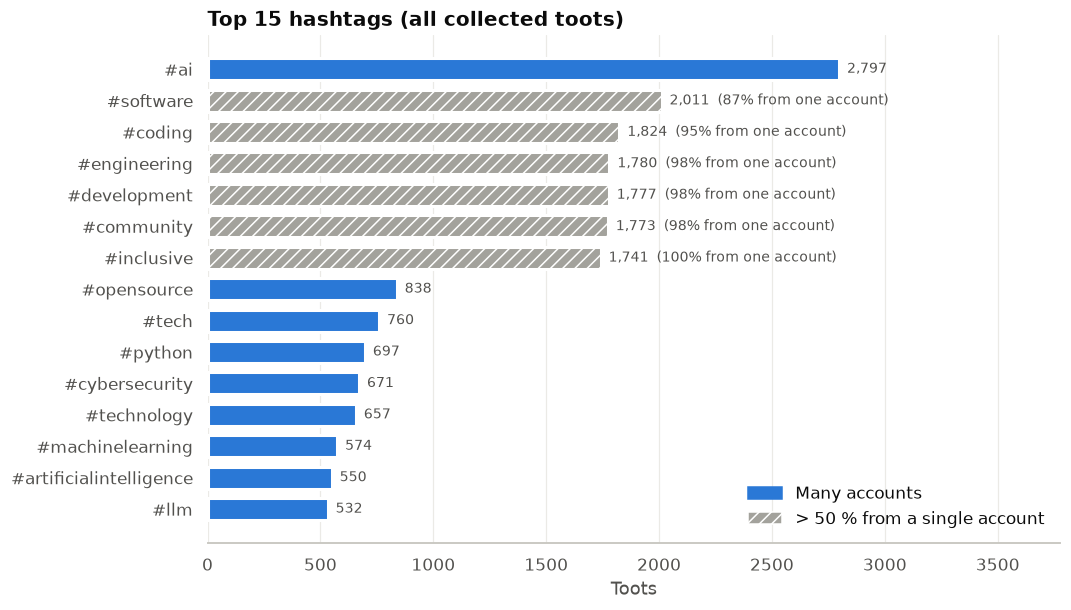

,hashtag,toot_count,user_count,top_user_share,top_user
0,ai,2797,784,0.191276,hackaday@www.urbanmind.net
1,software,2011,54,0.865738,hackaday@www.urbanmind.net
2,coding,1824,44,0.954496,hackaday@www.urbanmind.net
3,engineering,1780,22,0.978090,hackaday@www.urbanmind.net
4,development,1777,17,0.979741,hackaday@www.urbanmind.net
5,community,1773,16,0.981951,hackaday@www.urbanmind.net
6,inclusive,1741,1,1.000000,hackaday@www.urbanmind.net
7,opensource,838,311,0.193317,hackaday@www.urbanmind.net
8,tech,760,177,0.253947,techwire@gamefan.net
9,python,697,162,0.269727,hackaday@www.urbanmind.net


In [5]:
top_tags = sql("""
    WITH per_user AS (
        SELECT h.hashtag, t.user_id, count(*) AS n
        FROM toot_hashtags h JOIN toots t USING (toot_id)
        GROUP BY 1, 2
    ), top_user AS (
        SELECT DISTINCT ON (hashtag) hashtag, user_id, n FROM per_user ORDER BY hashtag, n DESC
    )
    SELECT b.hashtag, b.toot_count, b.user_count, u.n::float / b.toot_count AS top_user_share,
           (SELECT max(username) FROM toots WHERE user_id = u.user_id) AS top_user
    FROM batch_hashtag_totals b JOIN top_user u USING (hashtag)
    ORDER BY b.toot_count DESC LIMIT 15
""")
top_tags["single_account"] = top_tags.top_user_share > 0.5

fig, ax = plt.subplots(figsize=(10, 6))
data = top_tags.iloc[::-1]
colors = [GRAY if s else BLUE for s in data.single_account]
ax.barh("#" + data.hashtag, data.toot_count, color=colors, height=0.7, edgecolor="white", linewidth=2,
        hatch=["///" if s else "" for s in data.single_account])
for y, (count, share) in enumerate(zip(data.toot_count, data.top_user_share)):
    ax.text(count, y, f"  {count:,}" + (f"  ({share:.0%} from one account)" if share > 0.5 else ""),
            va="center", color=TEXT_2, fontsize=9)
ax.legend(handles=[Patch(color=BLUE, label="Many accounts"),
                   Patch(facecolor=GRAY, hatch="///", edgecolor="white", label="> 50 % from a single account")],
          loc="lower right", frameon=False)
ax.set_title("Top 15 hashtags (all collected toots)")
ax.set_xlabel("Toots")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, data.toot_count.max() * 1.35)
finish(fig, "3_top_hashtags")
top_tags[["hashtag", "toot_count", "user_count", "top_user_share", "top_user"]]

**Lecture.** Les volumes bruts trompent : 6 des 15 hashtags les plus fréquents (#software, #coding,
#engineering, #development, #community, #inclusive) viennent à 87–100 % d'**un seul compte**,
`hackaday@www.urbanmind.net`, un relais automatique qui met les mêmes hashtags sur chaque billet.
Sans lui, le classement réel est #ai, puis #opensource, #tech, #python, #cybersecurity : l'IA domine
nettement la conversation tech sur Mastodon. Le nombre de comptes distincts (`user_count`) est un meilleur
indicateur de popularité que le nombre de toots.

## 4. Distribution des sentiments

Toots en anglais notés par le modèle MLlib (régression logistique entraînée sur Sentiment140). Neutre :
probabilité « positif » entre 0,30 et 0,70.

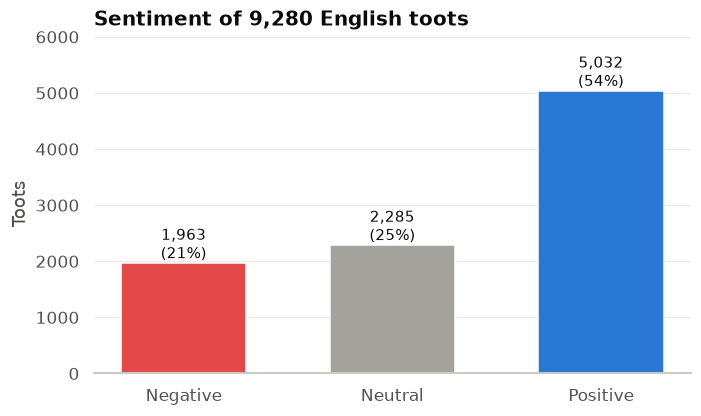

In [6]:
sentiments = sql("SELECT sentiment, count(*) AS toots FROM toot_sentiment GROUP BY 1")
order = ["negative", "neutral", "positive"]
sentiments = sentiments.set_index("sentiment").reindex(order).fillna(0).astype(int).reset_index()
total = sentiments.toots.sum()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(sentiments.sentiment.str.capitalize(), sentiments.toots,
       color=[SENTIMENT_COLORS[s] for s in sentiments.sentiment], width=0.6)
for x, n in enumerate(sentiments.toots):
    ax.text(x, n, f"{n:,}\n({n / total:.0%})", ha="center", va="bottom", color=TEXT, fontsize=10)
ax.set_title(f"Sentiment of {total:,} English toots")
ax.set_ylabel("Toots")
ax.set_ylim(0, sentiments.toots.max() * 1.2)
ax.grid(axis="x", visible=False)
finish(fig, "4_sentiment_distribution")

**Lecture.** Une majorité de toots positifs (54 %), 25 % neutres et 21 % négatifs. Le ton positif s'explique
en partie par la nature des toots tech : annonces de produits, tutoriels, partages de projets.

Exemples de toots aux probabilités extrêmes (vérification qualitative du modèle) :

In [7]:
pd.set_option("display.max_colwidth", 120)
sql("""
    (SELECT sentiment, round(probability::numeric, 3) AS p_positive,
            left(regexp_replace(content, '\\s+', ' ', 'g'), 120) AS toot
     FROM toot_sentiment ORDER BY probability DESC LIMIT 5)
    UNION ALL
    (SELECT sentiment, round(probability::numeric, 3), left(regexp_replace(content, '\\s+', ' ', 'g'), 120)
     FROM toot_sentiment ORDER BY probability ASC LIMIT 5)
""")

,sentiment,p_positive,toot
0,positive,1.0,"The Quest Begins (The ""Why"") I still remember the first time I got a job offer after months of interviewing. The rec..."
1,positive,1.0,"Introduction SQL is often introduced as a language for retrieving data, but for data scientists it is much more than..."
2,positive,1.0,AI clusters depend on two types of networking to function effectively for modern workloads. Scale-up networking conn...
3,positive,1.0,Phasecraft and NVIDIA recently announced a significant breakthrough in quantum simulation performance by combining s...
4,positive,1.0,"Introduction In modern content management projects, developers often spend time on repetitive tasks such as validati..."
5,negative,0.0,A messy refactor fails when the new shape changes hidden behavior. Characterization tests record current outputs bef...
6,negative,0.0,"A closed socket is an infrastructure event, and it must never become a task score in the eval ledger. When those two..."
7,negative,0.0,I opened these notes because two runs looked identical in the log and still disagreed in the answer. The prompt sent...
8,negative,0.0,"The scene below is a worked example, not a field report. A missing currency code is slipping into a warehouse export..."
9,negative,0.0,"Day 58 of DevOps, Day 8 of Azure. Both tasks today had a gap between ""created"" and ""working"". A Deployment reports 1..."


**Limites du modèle.** Les toots aux probabilités extrêmes (0 ou 1) sont des textes **longs** : la régression
logistique additionne le poids de chaque mot, donc plus le texte est long, plus elle est catégorique.
Les toots « négatifs » ci-dessus sont des textes techniques neutres (tests, logs, données manquantes) :
le modèle a appris sur des tweets personnels de 2009, où « fails », « missing » ou « gap » expriment
une émotion. Ce **biais de domaine** est la principale limite du modèle sur les toots tech.

## 5. Sentiment par hashtag (bonus)

Répartition des sentiments pour les 12 hashtags les plus fréquents parmi les toots notés, triés par part
de toots positifs.

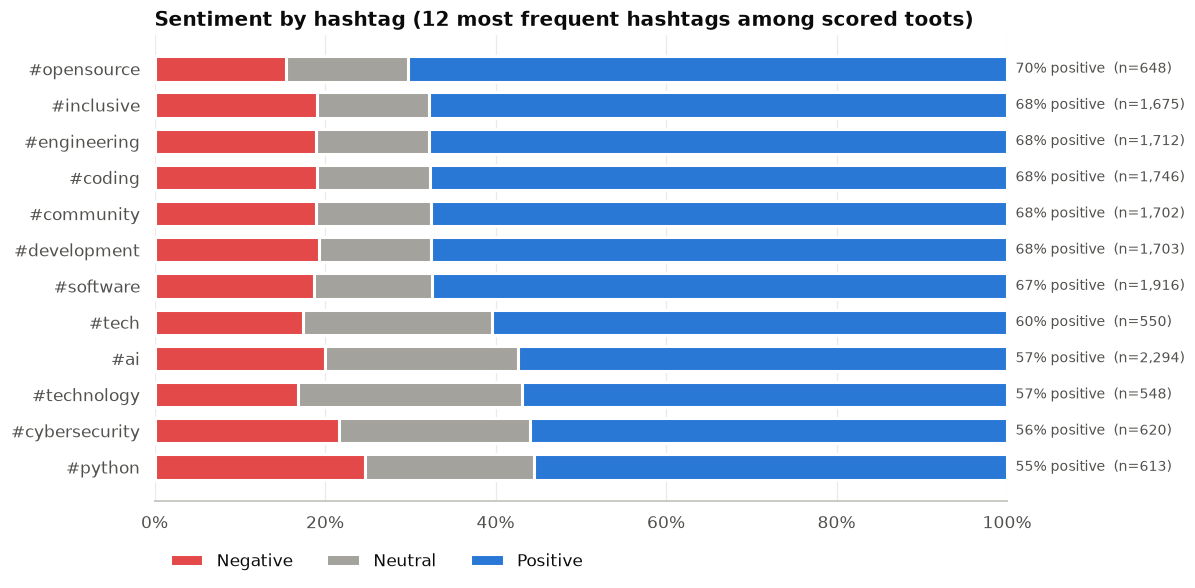

In [8]:
by_tag = sql("""
    WITH top AS (
        SELECT h.hashtag FROM toot_sentiment s JOIN toot_hashtags h USING (toot_id)
        GROUP BY 1 ORDER BY count(*) DESC LIMIT 12
    )
    SELECT h.hashtag, s.sentiment, count(*) AS toots
    FROM toot_sentiment s JOIN toot_hashtags h USING (toot_id) JOIN top USING (hashtag)
    GROUP BY 1, 2
""")
shares = by_tag.pivot(index="hashtag", columns="sentiment", values="toots").reindex(columns=order).fillna(0)
counts = shares.sum(axis=1)
shares = shares.div(counts, axis=0).sort_values("positive")

fig, ax = plt.subplots(figsize=(10, 5.5))
left = np.zeros(len(shares))
for s in order:
    ax.barh("#" + shares.index, shares[s], left=left, color=SENTIMENT_COLORS[s], label=s.capitalize(),
            height=0.7, edgecolor="white", linewidth=2)
    left += shares[s]
for y, (tag, pos) in enumerate(shares.positive.items()):
    ax.text(1.01, y, f"{pos:.0%} positive  (n={int(counts[tag]):,})", va="center", color=TEXT_2, fontsize=9)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlim(0, 1)
ax.set_title("Sentiment by hashtag (12 most frequent hashtags among scored toots)")
ax.legend(ncols=3, loc="upper left", bbox_to_anchor=(0, -0.08), frameon=False)
ax.grid(axis="y", visible=False)
finish(fig, "5_sentiment_by_hashtag")

**Lecture.** Les 6 hashtags du relais Hackaday ont exactement le même profil (≈ 68 % positifs) : ce sont
les mêmes toots. Parmi les hashtags portés par de nombreux comptes, #opensource est le plus positif
(70 %), tandis que #python, #cybersecurity et #ai sont plus partagés (55–57 % positifs) : la
cybersécurité parle de failles et d'attaques, et l'IA suscite des débats.

## 6. Optimisation du job batch

Médiane de 3 exécutions par scénario, sur les mêmes données (`batch/benchmark.sh`). Le temps total se
décompose en lecture PostgreSQL (avec la mise en cache pour `cache` et `optimized`) et calculs + écritures.

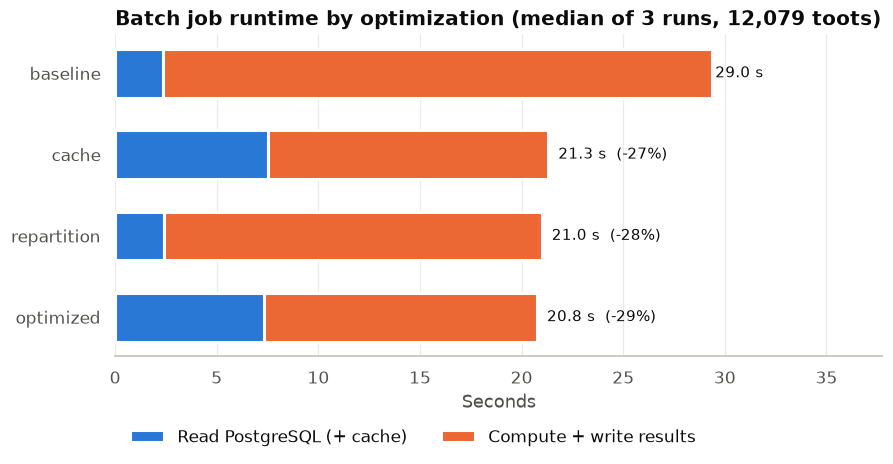

,runs,toots,load_s,compute_s,total_s
scenario,,,,,
baseline,3,12079,2.3,27.0,29.0
cache,3,12079,7.5,13.8,21.3
repartition,3,12079,2.4,18.6,21.0
optimized,3,12079,7.3,13.4,20.8


In [9]:
bench = sql("""
    WITH last_run AS (SELECT max(data_until) AS until FROM batch_benchmarks WHERE data_until IS NOT NULL)
    SELECT scenario, count(*) AS runs, max(toot_count) AS toots,
           percentile_cont(0.5) WITHIN GROUP (ORDER BY load_s)            AS load_s,
           percentile_cont(0.5) WITHIN GROUP (ORDER BY total_s - load_s)  AS compute_s,
           percentile_cont(0.5) WITHIN GROUP (ORDER BY total_s)           AS total_s
    FROM batch_benchmarks, last_run
    WHERE data_until = last_run.until
    GROUP BY scenario
""").set_index("scenario").reindex(["baseline", "cache", "repartition", "optimized"]).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(bench.index, bench.load_s, color=BLUE, height=0.6, label="Read PostgreSQL (+ cache)",
        edgecolor="white", linewidth=2)
ax.barh(bench.index, bench.compute_s, left=bench.load_s, color="#eb6834", height=0.6,
        label="Compute + write results", edgecolor="white", linewidth=2)
baseline = bench.loc["baseline", "total_s"]
for y, total in enumerate(bench.total_s):
    gain = "" if y == len(bench) - 1 else f"  ({total / baseline - 1:+.0%})"
    ax.text(total, y, f"  {total:.1f} s{gain}", va="center", color=TEXT, fontsize=10)
ax.set_xlim(0, bench.total_s.max() * 1.3)
ax.set_title(f"Batch job runtime by optimization (median of {int(bench.runs.min())} runs, "
             f"{int(bench.toots.max()):,} toots)")
ax.set_xlabel("Seconds")
ax.legend(ncols=2, loc="upper left", bbox_to_anchor=(0, -0.18), frameon=False)
ax.grid(axis="y", visible=False)
finish(fig, "6_batch_optimization")
bench.iloc[::-1].round(1)

**Lecture.** Le cache **double le coût de lecture** (matérialisation en mémoire) mais **divise par 2 le
temps de calcul** : les 4 sorties ne relisent plus PostgreSQL. Le repartitionnement sur `toot_id`
(4 partitions au lieu de 200) supprime les shuffles des jointures et réduit le nombre de tâches.
Combinés : −29 %. Le gain reste modeste car le volume est petit : une part importante du temps est un
coût fixe (démarrage des tâches, connexions JDBC). Sur un historique de plusieurs millions de toots,
l'effet du cache serait bien plus marqué.

## 7. Qualité du modèle de sentiment

Jeu de test Sentiment140 (20 %, environ 320 000 tweets) : comparaison des deux classifieurs et matrice de
confusion du modèle retenu.

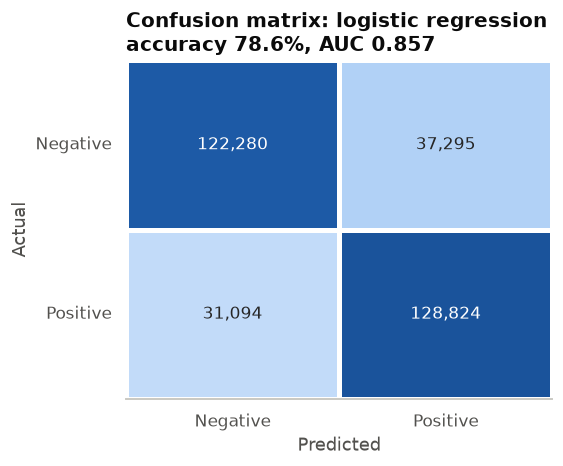

,model_name,selected,accuracy,f1,auc,manual_accuracy,neutral_margin,manual_3class_accuracy
0,logistic_regression,True,0.7859,0.7859,0.8575,0.7967,0.2,0.5743
1,naive_bayes,False,0.7615,0.7615,0.8281,NaN,NaN,NaN


In [10]:
metrics = sql("""
    SELECT DISTINCT ON (model_name) model_name, selected, accuracy, f1, auc, tn, fp, fn, tp,
           manual_accuracy, neutral_margin, manual_3class_accuracy
    FROM sentiment_model_metrics ORDER BY model_name, trained_at DESC
""")
best = metrics[metrics.selected].iloc[0]
confusion = pd.DataFrame([[best.tn, best.fp], [best.fn, best.tp]],
                         index=["Negative", "Positive"], columns=["Negative", "Positive"])

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion / confusion.values.sum(), annot=confusion.map(lambda n: f"{n:,}"), fmt="",
            cmap=SEQUENTIAL, vmin=0, vmax=0.5, linewidths=2, linecolor="white", cbar=False, ax=ax,
            annot_kws={"fontsize": 11})
ax.set_title(f"Confusion matrix: {best.model_name.replace('_', ' ')}\naccuracy {best.accuracy:.1%}, AUC {best.auc:.3f}")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.tick_params(axis="y", rotation=0)
finish(fig, "7_confusion_matrix")
metrics.drop(columns=["tn", "fp", "fn", "tp"]).round(4)

**Lecture.** La régression logistique est retenue : 78,6 % d'exactitude et une AUC de 0,857 contre 76,2 %
et 0,828 pour Naive Bayes. Les erreurs sont équilibrées entre les deux classes (37 k faux positifs,
31 k faux négatifs). Sur les 498 tweets annotés à la main, l'exactitude positif/négatif est de 79,7 %,
mais tombe à 57,4 % avec la classe neutre : distinguer un texte neutre d'un texte faiblement polarisé
reste difficile avec un modèle sac de mots.